# Solar Filament Segmentation Challenge 2026: full pipeline

This notebook reproduces our submitted predictions (`submission/ens10b18_r40.csv`) from the stored model weights, without retraining.

**Pipeline**

1. **Pre-processing:** each 2048 x 2048 H-alpha photo is shrunk to 1024 x 1024 and divided by the median brightness of its solar disk (clip 0 to 2.5, minus 1).
2. **Models:** two groups of U-Nets, five models each (one per cross-validation fold): ResNet-34 encoder (`weights/resnet34_fold*.pt`) and EfficientNetV2-S encoder (`weights/effv2s_fold*.pt`). Trained with batch 18 for 8000 steps (see `src/`).
3. **Prediction:** every model predicts the photo and its mirror image (averaged); the five models of a group are averaged; the two groups are averaged with equal weight.
4. **Post-processing:** the probability map is enlarged to 2048 x 2048 and cut at 0.40; each 8-connected blob is one filament, kept if its area is at least 300 px and its mean probability at least 0.80 (if none survives, the most confident blob is kept).
5. **Output:** one RLE mask per filament in `outputs/submission.csv`, then a check against the submitted file.

**Requirements:** `pip install -r requirements.txt`. A CUDA GPU is recommended (about 3 minutes); on CPU it runs, but much more slowly.

**Data:** set `TEST_DIR` below (or the environment variable `TEST_DIR`) to the competition's `test/test_images` folder. On Kaggle it is found automatically.

In [1]:
import os, glob, time
from pathlib import Path
import numpy as np, pandas as pd, cv2
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from scipy import ndimage as ndi
from pycocotools import mask as mu

TEST_DIR = os.environ.get("TEST_DIR", "")            # e.g. r"C:\data\MAGFiLO_1.0_Kaggle_2026\test\test_images"
if not TEST_DIR:
    found = [d for root in ("/kaggle/input", "data", "..") for d in glob.glob(f"{root}/**/test_images", recursive=True) if os.path.isdir(d)]
    assert found, "test_images folder not found: set TEST_DIR to the competition's test/test_images folder"
    TEST_DIR = found[0]
WEIGHTS = Path("weights")
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
RES, H, W = 1024, 2048, 2048
THR, MIN_AREA, MIN_MEAN = 0.40, 300, 0.80               # post-processing rule
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("test photos:", TEST_DIR, "| device:", torch.cuda.get_device_name(0) if dev.type == "cuda" else "CPU")


test photos: C:\Users\Divyansh\Downloads\MAGFiLO_1.0_Kaggle_2026\test\test_images | device: NVIDIA GeForce RTX 5050 Laptop GPU


## 1. Pre-processing

In [2]:
def load_small(path):
    g = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE).astype(np.float32)
    return cv2.resize(g, (RES, RES), interpolation=cv2.INTER_AREA)

def norm_img(g):
    """Divide by the median brightness of the solar disk (pixels above 25), clip to 0..2.5, shift by -1."""
    med = max(float(np.median(g[g > 25])) if (g > 25).any() else 1.0, 1.0)
    return (np.clip(g / med, 0, 2.5) - 1.0).astype(np.float32)

names = [p for p in sorted(Path(TEST_DIR).iterdir()) if p.suffix.lower() in (".jpg", ".jpeg")]
X = [norm_img(load_small(p)).astype(np.float16) for p in names]          # stored as float16, as in training
print(len(X), "test photos loaded")


180 test photos loaded


## 2. Models (same definitions as in training; the weights come from `weights/`)

In [3]:
def conv_bn(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
CH = (64, 64, 128, 256, 512)

class ResNetUNet(nn.Module):
    """U-Net with a ResNet-34 encoder and our own decoder (two conv-BN-ReLU blocks per level, bilinear up-sampling)."""
    def __init__(self):
        super().__init__()
        enc = torchvision.models.resnet34(weights=None)
        self.l0 = nn.Sequential(enc.conv1, enc.bn1, enc.relu); self.pool = enc.maxpool
        self.l1, self.l2, self.l3, self.l4 = enc.layer1, enc.layer2, enc.layer3, enc.layer4
        c0, c1, c2, c3, c4 = CH
        self.d4 = nn.Sequential(conv_bn(c4 + c3, 256), conv_bn(256, 256)); self.d3 = nn.Sequential(conv_bn(256 + c2, 128), conv_bn(128, 128))
        self.d2 = nn.Sequential(conv_bn(128 + c1, 64), conv_bn(64, 64)); self.d1 = nn.Sequential(conv_bn(64 + c0, 64), conv_bn(64, 64))
        self.d0 = nn.Sequential(conv_bn(64, 32), conv_bn(32, 32)); self.head = nn.Conv2d(32, 1, 1)
    def forward(self, x):
        x = x.repeat(1, 3, 1, 1); x0 = self.l0(x); x1 = self.l1(self.pool(x0)); x2 = self.l2(x1); x3 = self.l3(x2); x4 = self.l4(x3)
        up = lambda a, b: torch.cat([F.interpolate(a, size=b.shape[-2:], mode="bilinear", align_corners=False), b], 1)
        d = self.d4(up(x4, x3)); d = self.d3(up(d, x2)); d = self.d2(up(d, x1)); d = self.d1(up(d, x0))
        return self.head(self.d0(F.interpolate(d, scale_factor=2, mode="bilinear", align_corners=False)))

class EffUNet(nn.Module):
    """U-Net with an EfficientNetV2-S encoder (segmentation-models-pytorch)."""
    def __init__(self):
        super().__init__()
        import segmentation_models_pytorch as smp
        self.m = smp.Unet("tu-tf_efficientnetv2_s", encoder_weights=None, in_channels=3, classes=1)
    def forward(self, x): return self.m(x.repeat(1, 3, 1, 1))


## 3. Prediction: mirror averaging, five fold models per group, two groups

In [4]:
@torch.no_grad()
def predict(model, arrs):
    model.eval(); out = []
    for a in arrs:
        x = torch.from_numpy(np.asarray(a, np.float32))[None, None].to(dev)
        if dev.type == "cuda":
            with torch.autocast("cuda", dtype=torch.float16):
                p = 0.5 * (torch.sigmoid(model(x).float()) + torch.sigmoid(model(x.flip(-1)).float()).flip(-1))
            if torch.isnan(p).any():                                   # half-precision safety net
                p = 0.5 * (torch.sigmoid(model(x)) + torch.sigmoid(model(x.flip(-1))).flip(-1))
        else:
            p = 0.5 * (torch.sigmoid(model(x)) + torch.sigmoid(model(x.flip(-1))).flip(-1))
        out.append((p[0, 0].cpu().numpy() * 255).round().astype(np.uint8))
    return out

def predict_group(cls, prefix):
    probs = np.zeros((len(X), RES, RES), np.float32)
    for f in range(5):
        m = cls().to(dev)
        m.load_state_dict(torch.load(WEIGHTS / f"{prefix}_fold{f}.pt", map_location=dev))
        probs += np.stack(predict(m, X)).astype(np.float32) / 5
        print(f"  {prefix} fold {f} done ({time.time() - t0:.0f}s)", flush=True)
        del m
        if dev.type == "cuda": torch.cuda.empty_cache()
    return probs.round().astype(np.uint8)                                # 0-255 probability map per photo

t0 = time.time()
res = predict_group(ResNetUNet, "resnet34")
eff = predict_group(EffUNet, "effv2s")
ens = (0.5 * (res.astype(np.float32) + 0.5 * (eff.astype(np.float32) + eff.astype(np.float32)))).round().astype(np.uint8)
print("ensemble ready:", ens.shape)


  resnet34 fold 0 done (18s)


  resnet34 fold 1 done (32s)


  resnet34 fold 2 done (46s)


  resnet34 fold 3 done (60s)


  resnet34 fold 4 done (74s)


C:\Users\Divyansh\.conda\envs\solar\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


... (2 outputs left out)

  effv2s fold 2 done (123s)


  effv2s fold 3 done (138s)


  effv2s fold 4 done (152s)


ensemble ready: (180, 1024, 1024)


## 4. Post-processing: from probabilities to separate filaments

In [5]:
def extract(prob_u8, thr, min_area=100, max_comps=60):
    """Enlarge to 2048, cut at thr, 8-connected blobs -> list of (area, mean_prob, peak_prob, RLE)."""
    up = cv2.resize(prob_u8, (W, H), interpolation=cv2.INTER_LINEAR)
    n, lab, st, _ = cv2.connectedComponentsWithStats((up > int(thr * 255)).astype(np.uint8), connectivity=8)
    comps = []
    if n > 1:
        areas = st[1:, cv2.CC_STAT_AREA]
        keep = [k for k in np.argsort(-areas)[:max_comps] if areas[k] >= min_area]
        if keep:
            ids = np.array(keep) + 1
            mean, mx = ndi.mean(up, lab, ids), ndi.maximum(up, lab, ids)
            for k, mn, pk in zip(ids, mean, mx):
                x, y, w, h = st[k, :4]
                m = np.zeros((H, W), np.uint8, order="F")
                m[y:y + h, x:x + w] = (lab[y:y + h, x:x + w] == k)
                comps.append((int(st[k, 4]), float(mn) / 255, float(pk) / 255, mu.encode(m)))
    return comps

rows, kept_all = [], []
for p, prob in zip(names, ens):
    cs = extract(prob, THR)
    keep = [c for c in cs if c[0] >= MIN_AREA and c[1] >= MIN_MEAN]
    if not keep and cs:
        keep = [max(cs, key=lambda c: c[1])]                             # never leave a photo empty
    kept_all.append(keep)
    for j, c in enumerate(keep, 1):
        rows.append({"filament_id": f"{p.stem}_{j}", "segmentation_rle": c[3]["counts"].decode("ascii")})
sub = pd.DataFrame(rows)
sub.to_csv(OUT_DIR / "submission.csv", index=False)
print(f"outputs/submission.csv: {len(sub)} filaments, {len(sub) / len(names):.2f} per photo")


outputs/submission.csv: 1091 filaments, 6.06 per photo


## 5. Check against the submitted file

On the machine that made the submission the two files are identical; on another GPU, tiny numerical differences can change a few outlines.

In [6]:
ref = pd.read_csv("submission/ens10b18_r40.csv")
per_photo = lambda d: d.filament_id.str.rsplit("_", n=1).str[0].value_counts()
same_counts = (per_photo(sub).reindex(per_photo(ref).index).fillna(0) == per_photo(ref)).mean()
same_rle = len(set(sub.segmentation_rle) & set(ref.segmentation_rle)) / len(ref)
print(f"submitted: {len(ref)} filaments | reproduced: {len(sub)} filaments")
print(f"photos with the same number of filaments: {same_counts:.1%} | identical outlines: {same_rle:.1%}")


submitted: 1091 filaments | reproduced: 1091 filaments
photos with the same number of filaments: 100.0% | identical outlines: 100.0%


## 6. Example: predicted filaments on three test photos

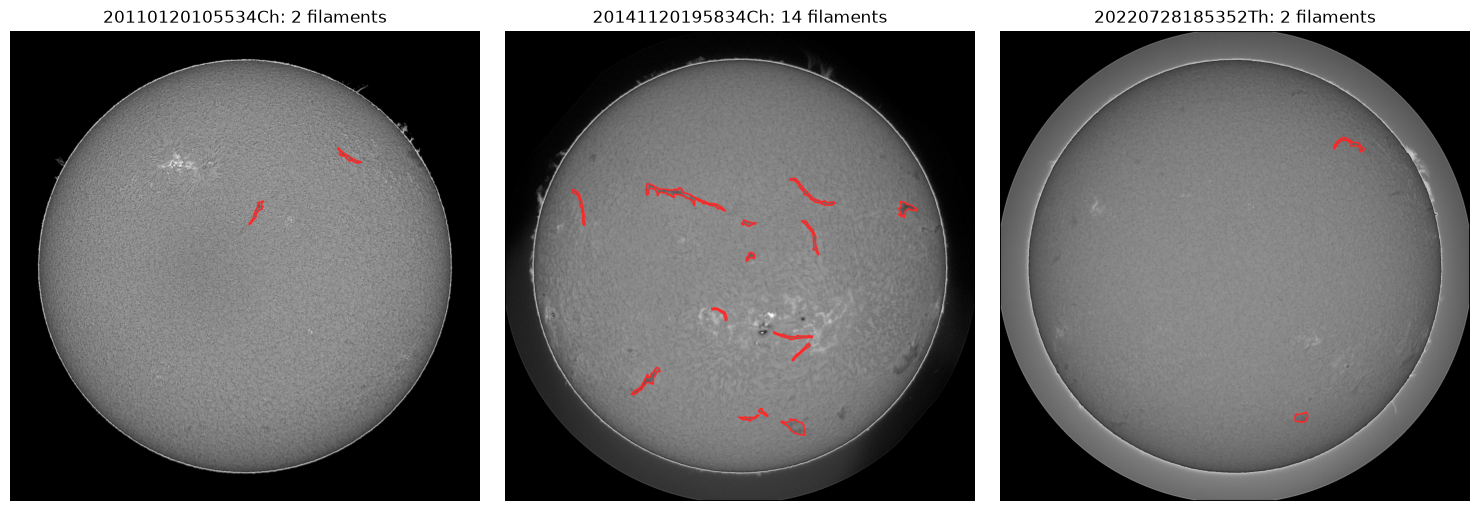

In [7]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, i in zip(axes, np.linspace(0, len(names) - 1, 3).astype(int)):
    img = cv2.resize(cv2.imread(str(names[i]), cv2.IMREAD_GRAYSCALE), (1024, 1024), interpolation=cv2.INTER_AREA)
    rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    for c in kept_all[i]:
        m = cv2.resize(mu.decode(c[3]), (1024, 1024), interpolation=cv2.INTER_NEAREST)
        cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, cnts, -1, (255, 40, 40), 2)
    ax.imshow(rgb); ax.set_title(f"{names[i].stem}: {len(kept_all[i])} filaments"); ax.axis("off")
plt.tight_layout(); plt.show()


## 7. Training (not run here)

The weights were trained on Kaggle (2 x NVIDIA T4, about 90 minutes per model) with the scripts in `src/`:

```
EXP=resnet34_b18 RES=1024 BATCH=18 ITERS=8000 SEED=42 FOLDS=0 python src/train_resnet.py
EXP=effv2s_b18 ENCODER=tu-tf_efficientnetv2_s RES=1024 BATCH=18 ITERS=8000 SEED=42 FOLDS=0 python src/train_effnet.py
```

(repeated for FOLDS=1..4). Training uses random 512 x 512 windows (70% centred on a filament), flips, 90-degree rotations and brightness jitter; the target is the average of all annotators' masks; the loss is BCE + Dice; AdamW (learning rate 3e-4, weight decay 1e-4) with a one-cycle schedule in mixed precision. The 5-fold split is grouped by calendar day and stratified by station; it is stored in `data/folds_photos.csv`.